In [17]:
import matplotlib.pyplot as plt
from random_variate_generator import RandomVariateGenerator
from review_queue import simulate_queue, results_summary

In [18]:
SEED = 42
NUM_REVIEWERS = 2
MEAN_REVIEW_TIME = 10      # minutes
NUM_JOBS = 20
GAP = 3                    # between arrivals

In [19]:
urv = RandomVariateGenerator(SEED)
arrivals = [i * GAP for i in range(NUM_JOBS)]
review_times = [urv.exponential(rate=1/MEAN_REVIEW_TIME) for _ in arrivals]

In [20]:
results = simulate_queue([0, 1, 2, 10], [5, 5, 5, 5], num_reviewers=2)

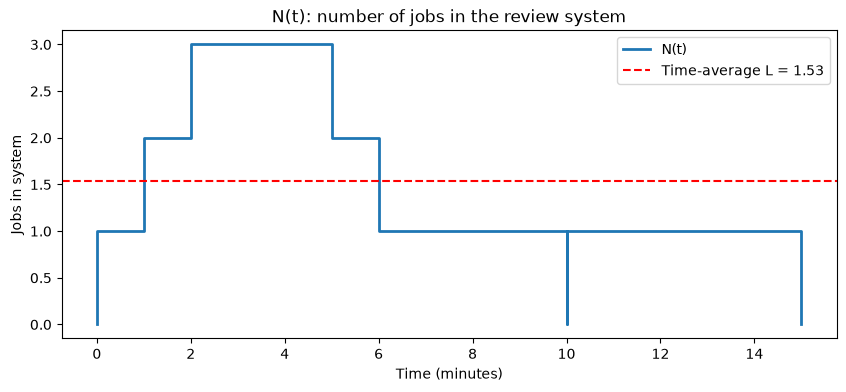

In [6]:
# Each job: arrival (+1), finish (-1); at a tie, the departure is processed first
events = []
for customer in results:
    events.append((customer["arrival"], +1))
    events.append((customer["finish"], -1))
events.sort()

# Running count of jobs in the system
times, counts = [0], [0]
count = 0
for time, change in events:
    count += change
    times.append(time)
    counts.append(count)

# Time-average (area under N(t) / end time)
area = sum(counts[i] * (times[i + 1] - times[i]) for i in range(len(times) - 1))
L = area / times[-1]

plt.figure(figsize=(10, 4))
plt.step(times, counts, where="post", linewidth=2, label="N(t)")
plt.axhline(L, color="red", linestyle="--", label=f"Time-average L = {L:.2f}")
plt.xlabel("Time (minutes)")
plt.ylabel("Jobs in system")
plt.title("N(t): number of jobs in the review system")
plt.legend()
plt.show()

In [21]:
import pandas as pd

summary = results_summary(results, NUM_REVIEWERS)
summary.update({"seed": SEED, 
                "num_reviewers": NUM_REVIEWERS, 
                "mean_review_time": MEAN_REVIEW_TIME,
                "num_jobs": NUM_JOBS, 
                "gap": GAP})

pd.DataFrame(results).to_csv("data/queue_results.csv", index=False)
pd.DataFrame([summary]).to_csv("data/queue_summary.csv", index=False)

pd.DataFrame([summary])

,avg_wait,W,lambda,utilization,L,Lq,seed,num_reviewers,mean_review_time,num_jobs,gap
0,0.75,5.75,0.266667,0.666667,1.533333,0.2,42,2,10,20,3
